# pupilread tutorial notebook

This notebook goes with the article *Pupillometry for L2 reading research: A step-by-step tutorial for eye-tracking researchers*.
It holds the code boxes **Python 1 to 5** from the article, run on the data of all 45 readers
(`pupilread_paper_data.zip`, attached to the v1.1.1 release on GitHub).

**How to use it**

- **Just reading?** All outputs (tables, figures, lists) are saved below each box, so you can follow every step without running anything.
- **Running it yourself?** Run the boxes in order, from top to bottom. Each box uses what the box before it made.
  Python 2 takes a few minutes, because it reads every sample of every reader.

The section numbers (for example, Section 3.3) refer to the article.

## Python 1. Installing pupilread and loading the data

Install pupilread once, then load it in every session.
To reproduce our results, download `pupilread_paper_data.zip` (388 MB) from the v1.1.1 release page and unzip it.
Then tell Python where the unzipped folder is.

In [1]:
# Step 1: install pupilread. In a Spyder or Jupyter console, run the line
# below without the first "#" (in a terminal, also leave out the %):
# %pip install https://github.com/Amberberwang1/pupillometry-L2-reading-tutorial/archive/refs/tags/v1.1.1.zip

# Step 2: to follow our stages outlined in the paper (Python 2 to 5) and reproduce our results, download
# pupilread_paper_data.zip (388 MB) from Assets on the v1.1.1 release
# page and unzip it:
# https://github.com/Amberberwang1/pupillometry-L2-reading-tutorial/releases/tag/v1.1.1

# Step 3: load pupilread and go to the data folder.
import pupilread as pr
# Optional: check that pupilread works on simulated data (3 readers)
pr.make_example("example")

# Replace the path with that of your unzipped pupilread_paper_data folder
# (or of your own data, laid out in the same way):
import os
os.chdir("pupilread_paper_data")

## Python 2. Blink handling and trial exclusion (Section 3.2)

For every reader, this box:

1. reads the three EyeLink reports (samples, messages, fixations);
2. marks blinks, removes 100 ms of data on each side of every blink, and removes brief artifacts where pupil size changes too fast (the speed filter);
3. excludes two kinds of trial: trials we listed as skimmed or incomplete (`exclusions.csv`), and trials with less than 50% valid samples;
4. keeps the data as 20 ms averages (bins, Section 3.3).

It then prints data loss per text version, and how many trials were excluded for each reason.

**A warning you will see.** The sample report of reader 42 was exported twice, so every sample appears twice.
pupilread removes the copies and warns about it. The warning is expected and does not change the results.

In [2]:
# For every reader in the unzipped pupilread_paper_data folder: read the
# reports, mark blinks and exclude trials (about 3 min).
# 20 ms averages (bins, Section 3.3) are kept, because the sample reports
# hold every sample and together can exceed the memory of a computer
import pandas as pd
loss, excluded, raw, fixations = [], [], [], []
for r in pr.find_readers("readers"):            # report files per reader
    s = pr.read_eyelink(r["samples"], messages=r["messages"],
                        design="design.csv", reader=r["reader"])
    # option: s = pr.detect_blinks(s)            # no blink events
    s = pr.pad_blinks(s, pad_ms=100, pupil_range=(100, 10000),
                      speed_filter=True)        # + speed filter
    s, ex = pr.exclude_trials(s, min_valid=0.5, exclude="exclusions.csv")
    # option: s = pr.interpolate(s, max_gap_ms=1000)
    loss.append(pr.data_loss(s, by=None).trials)            # kept trials
    excluded.append(ex)
    raw.append(pr.bin(s, bin_ms=20, min_valid=0.5))         # 20 ms bins
    fixations.append(pr.read_fixations(r["fixations"], messages=r["messages"],
                                       design="design.csv", reader=r["reader"]))
loss, excluded = pd.concat(loss), pd.concat(excluded)
raw, fixations = pd.concat(raw), pd.concat(fixations)
table = pr.summarise(loss, by="version")          # data loss per version
print(table[["measure", "non-simplified", "simplified", "p"]].round(2))
print(excluded.loc[excluded["excluded"], "reason"].value_counts())

.../site-packages/pupilread/io.py:260: UserWarning: read_eyelink: .../pupilread_paper_data/readers/42/sample_report.txt: dropped 1,419,118 samples whose trial and time stamp repeat an earlier sample (duplicated rows in the report)
  warnings.warn(f"read_eyelink: {path}: dropped {int(dup.sum()):,} samples whose trial and time stamp repeat an "


         measure  non-simplified  simplified     p
0     duration_s           43.18       38.51  0.00
1    pct_invalid            6.72        6.85  0.57
2  pct_blink_pad            5.98        6.09  0.33
3      pct_valid           87.31       87.06  0.42
4     blink_rate            0.31        0.32  0.29
5   saccade_rate            3.51        3.52  0.39
reason
listed         60
valid < 50%    16
Name: count, dtype: int64


**What to look for.** Both versions should lose similar shares of samples.
In our data, 12.7% of samples were lost in non-simplified texts and 12.9% in simplified texts (100 minus `pct_valid`).

The counts show 60 listed trials, not the 61 in `exclusions.csv`. The 61st (reader 02, trial 21) has no samples at all, so there was nothing to exclude.
Another 16 trials had less than 50% valid samples.

## Python 3. Baseline correction and checks (Section 3.3)

**Check the window.** The first figure shows pupil size in the first 2 s after the text appears,
averaged over all readers and both text versions.
The baseline window (0–200 ms) must end before the pupil reacts to the text.

**Correct.** Each trial's baseline (its mean pupil size from 0 to 200 ms) is subtracted from every value in that trial.
The result is expressed as a percentage of the reader's mean pupil size.

**Check the baselines.** A blink in the baseline window makes the baseline too small,
and so every corrected value in that trial too large. The second figure shows every trial's baseline
as a percentage of the reader's mean, once with plain counts and once with small counts enlarged (a log scale).
Trials that stand alone at the far left are excluded with a cut-off (`min_pct`).

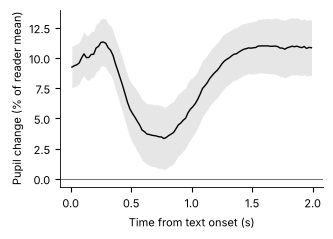

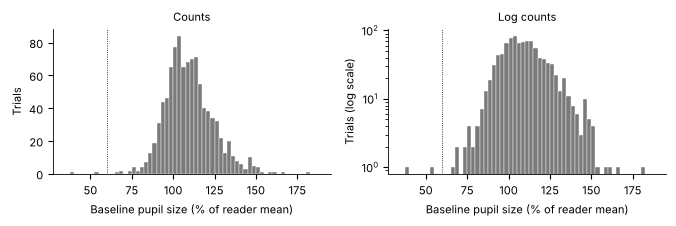

    reader  trial       reason
1       01      2  no baseline
39      02     17  no baseline
41      02     19  no baseline
145     08     15  no baseline
148     08     19  no baseline
174     09     23    below 60%
223     12      2  no baseline
228     12     11  no baseline
269     14      5  no baseline
324     16     14  no baseline
325     16     15  no baseline
327     16     18    below 60%
328     16     19  no baseline
329     16     20  no baseline
363     18      8  no baseline
409     20      7  no baseline
413     20     11  no baseline
422     21      6  no baseline
587     30     20  no baseline
694     36      9  no baseline
797     40     18  no baseline
822     41     22  no baseline


In [3]:
import matplotlib.pyplot as plt
# Check the window: pupil size in the first 2 s after text onset, averaged
# over all readers and both text versions; the pupil should react to the
# text only after the window ends
fig = pr.plot_grand_mean(pr.baseline(raw, method="none"), by=None,
                         bin_s=0.02, max_s=2, min_baseline_pct=None)
fig.savefig("check_window.png", dpi=150, bbox_inches="tight")
# Baseline window=(start, end) in ms from text onset; change it if needed
bins = pr.baseline(raw, window=(0, 200), method="subtractive",
                   scale="reader_mean")      # end before the reaction
low = pr.low_baselines(bins, min_pct=60)     # baselines below 60%
fig = pr.plot_baselines(low, min_pct=60)     # histogram to choose the cut-off
fig.savefig("check_baselines.png", dpi=150, bbox_inches="tight")
plt.show()                                   # show both figures
print(low.loc[low["low"], ["reader", "trial", "reason"]])

**What to look for.**

- *Window figure:* the drop caused by the text starts at about 250 ms, after the 0–200 ms window ends.
  The small rise before it cannot be a reaction to the text, because the pupil needs at least about 220 ms to respond (Mathôt et al., 2018).
- *Histogram:* most trials form one large group, which starts at 66%. Two trials stand alone at 39% and 55%, so we set `min_pct=60`.
- *List:* the trials that are excluded. "below 60%" marks the two lone trials.
  "no baseline" marks trials with no usable data in the window (for example, because a blink covered it). They cannot be corrected, so they are excluded too.

## Python 4. Gaze correction (Section 3.4)

When the eyes move across a line of text, the camera sees the pupil from a different angle,
and the measured pupil size changes even though the pupil does not.
This change happens at once, whereas real pupil responses start no earlier than about 220 ms after their cause (Mathôt et al., 2018).
The step in pupil size across each saccade therefore shows the error. `saccade_steps()` measures these steps, after taking out the slow change the pupil was already following just before the saccade.
`step_slopes()` then combines the steps into a map of the error across the screen for each recorded eye.
`correct_gaze()` then removes it from every 20 ms bin, before the baseline is subtracted.

In [4]:
steps = pr.saccade_steps(raw, fixations, after=(20, 120), before=100)
slopes = pr.step_slopes(steps, by="eye", method="map")     # error map per eye
print(slopes.round(2).T)                                   # the map of each eye
corrected = pr.correct_gaze(raw, slopes, method="steps")   # before baseline
# alternative: pr.correct_gaze(raw, layout="layout.csv",
#                              method="geometric")
corrected = pr.baseline(corrected, window=(0, 200), method="subtractive",
                        scale="reader_mean")

group           left     right
intercept      -0.01      0.00
n_saccades  41636.00  47697.00
x_0             4.50      0.42
x_100           4.06      0.82
x_200           3.09      0.82
x_300           2.31      0.79
x_400           1.20      0.43
x_500           0.00      0.00
x_600          -1.26     -0.66
x_700          -2.62     -1.30
x_800          -4.05     -2.18
x_900          -5.28     -3.13
x_1000         -6.65     -4.31
y_0            -1.57     -2.58
y_100          -0.57     -1.38
y_200           0.06     -0.02
y_300           0.40      0.52
y_400           0.00      0.00
y_500          -0.06     -0.39
y_600           0.46     -1.09
y_700          -2.07     -0.68
y_800          -2.07     -0.68


**What to look for.** One column per recorded eye. The rows `x_0` to `x_1000` give the error in measured pupil size at each horizontal position (in pixels), and `y_0` to `y_800` at each vertical position, as a percentage of the reader's mean. The error is set to 0 at the middle of the screen (`x_500`, `y_400`), so each value shows how much larger or smaller the pupil is measured there than in the middle. `n_saccades` is the number of saccades the map is based on.

In our data, the error grows faster on the right of the screen than on the left.

## Python 5. Trial means and the files for R (Sections 3.5 and 3.7)

The primary measure is each trial's mean corrected pupil size from 0.5 to 20 s.
This window is the same for both versions: it starts when cognitive effects on pupil size emerge
and ends before most trials do. Pupil size rises in the last 2 to 3 s before the key press that ends a trial, so the window also ends 3 s before the key press if that comes first. `export_for_r()` writes the files for the models in R to the folder `for_R`: the trial table, the trace averaged into 100 ms bins, and the R scripts.

In [5]:
# bins of Python 3; the window ends at 20 s or 3 s before the key press
trials = pr.trial_means(bins, window=(500, 20000), cut_before_keypress_ms=3000)
# Checks: the same window without the cut, and the whole trial
no_cut = pr.trial_means(bins, window=(500, 20000), cut_before_keypress_ms=0)
whole = pr.trial_means(bins, window=(500, None), cut_before_keypress_ms=0)
# files for R 1 and R 2, with the same cut
pr.export_for_r(trials, bins, folder="for_R", cut_before_keypress_ms=3000)

{'trials.csv': 'for_R/trials.csv',
 'bins.csv': 'for_R/bins.csv',
 'lmm.R': 'for_R/lmm.R',
 'gamm.R': 'for_R/gamm.R',
 'multiverse.R': 'for_R/multiverse.R',
 'pupilread.json': 'for_R/pupilread.json'}

## Next: the models in R (Section 3.7)

The folder `for_R` now holds the data files and the R scripts. `lmm.R` fits R 1, the mixed-effects model of the trial means,
and `gamm.R` fits R 2, the model of the time course. Both run without editing.

In our data, R 1 gave a difference between versions of 1.30% of the reader mean (95% CI [−0.29, 2.90], *p* = .109), from 981 trials.